In [1]:
import pandas as pd
import numpy as np

df = pd.read_parquet('prepared_dataset.parquet')
folds = pd.read_csv('cv_folds.csv')

In [13]:
target = 'pm2_5_corrected'
identifiers = ['station_id', 'day']

feature_cols = [c for c in df.columns if c not in [target] + identifiers and 'target' not in c]

df['day'] = pd.to_datetime(df['day'])
folds['train_start'] = pd.to_datetime(folds['train_start'])
folds['train_end'] = pd.to_datetime(folds['train_end'])
folds['test_start'] = pd.to_datetime(folds['test_start'])
folds['test_end'] = pd.to_datetime(folds['test_end'])

print(f"Total Features: {len(feature_cols)}")
print(f"Target Variable: {target}")

Total Features: 111
Target Variable: pm2_5_corrected


In [14]:
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import re

df_clean = df.copy()
df_clean.columns = [re.sub(r'[^\w]', '_', col) for col in df_clean.columns]

clean_target = re.sub(r'[^\w]', '_', target)
clean_features = [re.sub(r'[^\w]', '_', c) for c in feature_cols]

for col in clean_features:
    if df_clean[col].dtype == 'object':
        df_clean[col] = df_clean[col].astype('category')

results = []

for _, fold_row in folds.iterrows():
    fold_num = fold_row['fold']

    train_mask = (df_clean['day'] >= fold_row['train_start']) & (df_clean['day'] <= fold_row['train_end'])
    test_mask = (df_clean['day'] >= fold_row['test_start']) & (df_clean['day'] <= fold_row['test_end'])

    X_train, y_train = df_clean.loc[train_mask, clean_features], df_clean.loc[train_mask, clean_target]
    X_test, y_test = df_clean.loc[test_mask, clean_features], df_clean.loc[test_mask, clean_target]

    model = LGBMRegressor(random_state=42, n_estimators=100, verbose=-1)
    model.fit(X_train, y_train)

    preds = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    mae = mean_absolute_error(y_test, preds)
    r2 = r2_score(y_test, preds)

    results.append({'Fold': fold_num, 'RMSE': rmse, 'MAE': mae, 'R2': r2})
    print(f"Fold {fold_num} | RMSE: {rmse:.4f} | MAE: {mae:.4f} | R2: {r2:.4f}")

Fold 1 | RMSE: 11.3975 | MAE: 7.4459 | R2: 0.7140
Fold 2 | RMSE: 6.1631 | MAE: 4.5974 | R2: 0.8382
Fold 3 | RMSE: 5.5519 | MAE: 4.1223 | R2: 0.8076
Fold 4 | RMSE: 14.0796 | MAE: 8.8817 | R2: 0.7274
Fold 5 | RMSE: 5.0740 | MAE: 3.6879 | R2: 0.8417


In [16]:
results_df = pd.DataFrame(results)
print("\n=== Average Results ===")
print(results_df[['RMSE', 'MAE', 'R2']].mean())


=== Average Results ===
RMSE    8.453220
MAE     5.747050
R2      0.785783
dtype: float64


                     Feature  Importance
61    pm2_5_corrected_lag_1d         150
49        wind_speed_10m_min         101
95              wind_dir_sin          92
1                s5p_no2_col          82
47       wind_speed_10m_mean          78
96              wind_dir_cos          74
34        temperature_2m_std          72
48        wind_speed_10m_max          71
42      surface_pressure_std          71
37  relative_humidity_2m_min          69
64    pm2_5_corrected_lag_7d          66
0                   uv_index          66
38  relative_humidity_2m_std          65
57               pm10_lag_1d          61
36  relative_humidity_2m_max          60


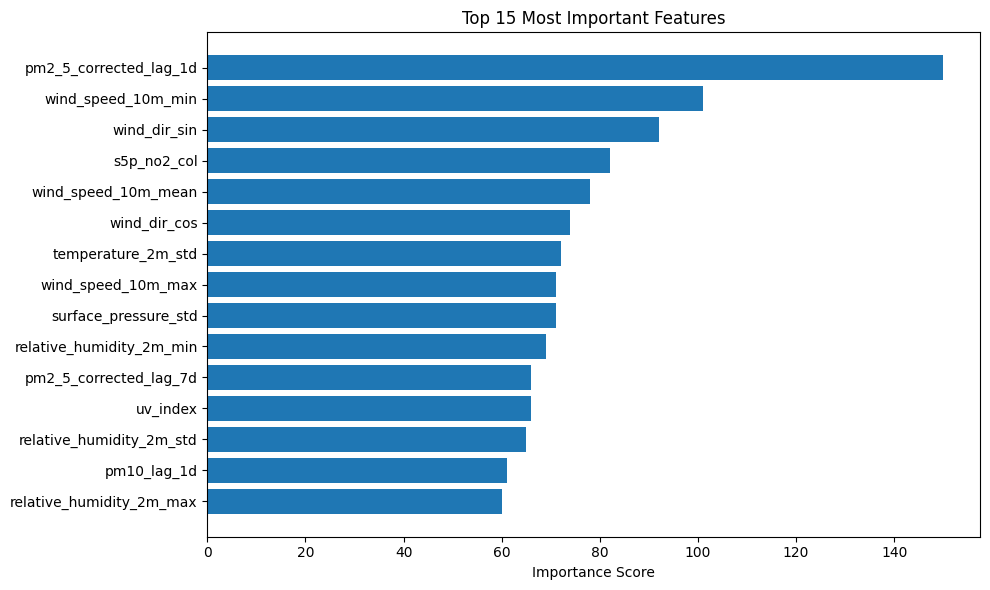

In [15]:
import matplotlib.pyplot as plt

importance_df = pd.DataFrame({
    'Feature': clean_features,
    'Importance': model.feature_importances_
}).sort_values(by='Importance', ascending=False)

print(importance_df.head(15))

plt.figure(figsize=(10, 6))
plt.barh(importance_df['Feature'].head(15)[::-1], importance_df['Importance'].head(15)[::-1])
plt.xlabel('Importance Score')
plt.title('Top 15 Most Important Features')
plt.tight_layout()
plt.show()

In [17]:
import joblib

results_df.to_csv('lgbm_cv_results.csv', index=False)
importance_df.to_csv('feature_importance.csv', index=False)

joblib.dump(model, 'lgb_model.pkl')

print("All results, feature importance, and trained model saved successfully!")

All results, feature importance, and trained model saved successfully!


In [18]:
import warnings
warnings.filterwarnings('ignore')

ts_data = df.groupby('day')['pm2_5_corrected'].mean().reset_index()
ts_data = ts_data.sort_values('day').set_index('day').asfreq('D')
ts_data['pm2_5_corrected'] = ts_data['pm2_5_corrected'].interpolate(method='linear')

In [19]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

sarima_results = []

for _, fold_row in folds.iterrows():
    fold_num = fold_row['fold']

    train = ts_data.loc[fold_row['train_start']:fold_row['train_end']]
    test = ts_data.loc[fold_row['test_start']:fold_row['test_end']]

    sarima_model = SARIMAX(train['pm2_5_corrected'], order=(1, 1, 1), seasonal_order=(1, 1, 1, 7))
    sarima_fit = sarima_model.fit(disp=False)
    sarima_preds = sarima_fit.forecast(steps=len(test))

    s_rmse = np.sqrt(mean_squared_error(test['pm2_5_corrected'], sarima_preds))
    s_mae = mean_absolute_error(test['pm2_5_corrected'], sarima_preds)
    s_r2 = r2_score(test['pm2_5_corrected'], sarima_preds)

    sarima_results.append({'Fold': fold_num, 'Model': 'SARIMA', 'RMSE': s_rmse, 'MAE': s_mae, 'R2': s_r2})
    print(f"SARIMA - Fold {fold_num} | RMSE: {s_rmse:.4f} | MAE: {s_mae:.4f} | R2: {s_r2:.4f}")

SARIMA - Fold 1 | RMSE: 24.0790 | MAE: 17.8035 | R2: -1.1025
SARIMA - Fold 2 | RMSE: 14.4350 | MAE: 12.2335 | R2: -0.1393
SARIMA - Fold 3 | RMSE: 9.5331 | MAE: 7.5489 | R2: -0.0236
SARIMA - Fold 4 | RMSE: 27.3849 | MAE: 19.0840 | R2: -0.4322
SARIMA - Fold 5 | RMSE: 16.6864 | MAE: 14.7064 | R2: -1.6021


In [20]:
from prophet import Prophet

prophet_results = []

for _, fold_row in folds.iterrows():
    fold_num = fold_row['fold']

    train = ts_data.loc[fold_row['train_start']:fold_row['train_end']].reset_index()
    test = ts_data.loc[fold_row['test_start']:fold_row['test_end']].reset_index()

    ph_train = train.rename(columns={'day': 'ds', 'pm2_5_corrected': 'y'})
    ph_test = test.rename(columns={'day': 'ds', 'pm2_5_corrected': 'y'})

    p_model = Prophet(daily_seasonality=True, weekly_seasonality=True, yearly_seasonality=False)
    p_model.fit(ph_train)
    p_forecast = p_model.predict(ph_test[['ds']])
    p_preds = p_forecast['yhat'].values

    p_rmse = np.sqrt(mean_squared_error(ph_test['y'], p_preds))
    p_mae = mean_absolute_error(ph_test['y'], p_preds)
    p_r2 = r2_score(ph_test['y'], p_preds)

    prophet_results.append({'Fold': fold_num, 'Model': 'Prophet', 'RMSE': p_rmse, 'MAE': p_mae, 'R2': p_r2})
    print(f"Prophet - Fold {fold_num} | RMSE: {p_rmse:.4f} | MAE: {p_mae:.4f} | R2: {p_r2:.4f}")

Prophet - Fold 1 | RMSE: 26.7448 | MAE: 20.8049 | R2: -1.5938
Prophet - Fold 2 | RMSE: 19.4537 | MAE: 17.4415 | R2: -1.0692
Prophet - Fold 3 | RMSE: 9.9797 | MAE: 8.1651 | R2: -0.1218
Prophet - Fold 4 | RMSE: 30.2815 | MAE: 21.5332 | R2: -0.7512
Prophet - Fold 5 | RMSE: 26.4020 | MAE: 25.2804 | R2: -5.5144


In [21]:
baseline_df = pd.DataFrame(sarima_results + prophet_results)
print("=== Baseline Models Average Results ===")
print(baseline_df.groupby('Model')[['RMSE', 'MAE', 'R2']].mean())

=== Baseline Models Average Results ===
              RMSE        MAE        R2
Model                                  
Prophet  22.572351  18.645026 -1.810074
SARIMA   18.423693  14.275248 -0.659941
